# PerfectPetClub — Task 2: ETL Pipeline for Customer Churn
**Module:** 7COM2005 Data Engineering | **Team:** P4G5 | **Notebook:** `notebooks/etl_pipeline.ipynb`

**Goal:** build a clean, one-row-per-customer dataset for analysing **churn** (a customer cancelling the auto-renew of their subscription) and write it to Parquet for the PySpark ML notebook (Task 3).

### Pipeline architecture
```
EXTRACT                         TRANSFORM                                   LOAD
SQLite (9 tables)  ─┐           clean_* functions  (types, DQ checks)
CRM report (CSV)   ─┤──►  raw   ─► build_features()  (feature engineering) ─► validate ─► data/processed/
Server log (CSV)   ─┤           ─► leakage audit + final validation                         processed_churn.parquet
Survey (CSV)       ─┘
```

### Key design decisions (be ready to justify these)
1. **Target:** `churn = 1 - auto_renew` (the brief defines churn as cancelling auto-renew). 
2. **Data-leakage prevention:** `subscription.end_date`, tenure, "days since last order" and raw activity *counts* are **deliberately excluded**. Customers who cancel stop ordering and logging in, so these columns would reveal the label (a model would look brilliant but be useless). All behavioural features are **rates per month of each customer's own observation window**, or ratios/trends, so they do not encode how long someone stayed.
3. **No PII in the output:** name, e-mail, password hash and address are dropped before loading.
4. **Missing delivery dates are flagged, not invented:** 1,090 orders (4.7%) have no expected/delivered date, spread across the whole year (so not only recent orders). We cannot tell whether they are in transit or simply unrecorded, so we create a `delivery_missing` flag instead of fabricating dates.

## 0. Setup: imports, paths, logging

In [1]:
import contextlib
import logging
import re
import sqlite3
import sys
from pathlib import Path

%pip install matplotlib seaborn scikit-learn numpy pandas
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import roc_auc_score

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")


def find_project_root(start=None) -> Path:
    """Walk upwards until a folder containing data/raw is found (works from notebooks/ or repo root)."""
    here = Path(start or Path.cwd()).resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "data" / "raw").is_dir():
            return candidate
    raise FileNotFoundError("Could not find the project root (a folder containing data/raw).")


ROOT = find_project_root()
RAW_DIR = ROOT / "data" / "raw"
PROCESSED_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "outputs" / "figures"
for folder in (PROCESSED_DIR, FIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

DB_PATH = RAW_DIR / "PerfectPetClub.db"
CRM_PATH = RAW_DIR / "PerfectPetClub_CRM_report.csv"
LOG_PATH = RAW_DIR / "PerfectPetClub_server_log.csv"
SURVEY_PATH = RAW_DIR / "PerfectPetClub_survey.csv"
OUTPUT_PARQUET = PROCESSED_DIR / "processed_churn.parquet"

# Logging goes to stdout so it is visible in the exported HTML.
logging.basicConfig(level=logging.INFO, stream=sys.stdout, force=True,
                    format="%(asctime)s | %(levelname)-7s | %(message)s", datefmt="%H:%M:%S")
logging.getLogger("matplotlib").setLevel(logging.WARNING)   # keep third-party chatter out of our log
log = logging.getLogger("etl")
log.info("Project root: %s", ROOT)


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached scikit_learn-1.9.1-cp312-cp312-win_amd64.whl.metadata (9.3 kB)
  Using cached scipy-1.18.1-cp312-cp312-win_amd64.whl.metadata (61 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.29.0-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.8.0-py3-none-any.whl.metadata (29 kB)
  Using cached cloudpickle-3.1.3-py3-none-any.whl.metadata (7.1 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   --- ------------------------------------ 0.8/8.3 MB 5.6 MB/s eta 0:00:02
   ---------- ----------------------------- 2.1/8.3 MB 5.9 MB/s eta 0:00:02
   --------------- ------------------------ 3.1/8.3 MB 5.9 MB/s eta 0:00:01
   ---------------------- ----------------- 4.7/8.3 MB 6.2 MB/s eta 0:00:01
   ------------------------------ --------- 6.3/8.3 MB 6.5 MB/s eta 0:00:01
   ---------------

## 1. Data-quality framework
Every cleaning step records its checks in a `DataQualityReport`. 
* **Critical** checks (e.g. primary key not unique, broken foreign key) **raise an error** and stop the pipeline.
* **Warning** checks (e.g. a few unmatched log-ins) are logged and reported but the pipeline continues.

The full report is printed at the end of the Transform stage, which gives us evidence of validation for the assessors.

In [2]:
class DataQualityError(Exception):
    """Raised when a critical data-quality check fails."""


class DataQualityReport:
    """Collects the outcome of every data-quality check made during the Transform stage."""

    def __init__(self):
        self.records = []

    def check(self, table: str, name: str, passed: bool, detail: str = "", critical: bool = False):
        status = "PASS" if passed else ("FAIL" if critical else "WARN")
        self.records.append({"table": table, "check": name, "status": status, "detail": detail})
        if passed:
            log.debug("DQ PASS | %s | %s", table, name)
        elif critical:
            log.error("DQ FAIL | %s | %s | %s", table, name, detail)
            raise DataQualityError(f"{table}: {name} - {detail}")
        else:
            log.warning("DQ WARN | %s | %s | %s", table, name, detail)

    def to_frame(self) -> pd.DataFrame:
        return pd.DataFrame(self.records)


def require_columns(df: pd.DataFrame, columns, table: str, dq: DataQualityReport):
    """Schema validation: every expected column must exist."""
    missing = [c for c in columns if c not in df.columns]
    dq.check(table, "schema: expected columns present", not missing, f"missing={missing}", critical=True)


dq = DataQualityReport()  # one report shared by the whole run

## 2. EXTRACT
Four sources: the SQLite sales database and three CSV files. Each extract function validates that the file exists, logs the row count, and raises a clear error otherwise.

> **Survey source note:** the brief says the survey is hosted on the university S3 store (VPN only). A copy is already in `data/raw/`, so the pipeline reads that. `download_survey_from_s3()` below shows how to refresh it; credentials are read from **environment variables** (never hard-coded in a repository).

In [3]:
def extract_sqlite_tables(db_path: Path) -> dict:
    """Read every user table of the SQLite database into a dict of DataFrames."""
    if not db_path.exists():
        raise FileNotFoundError(f"Database not found: {db_path}")
    with contextlib.closing(sqlite3.connect(db_path)) as conn:
        names = [r[0] for r in conn.execute(
            "SELECT name FROM sqlite_master WHERE type='table' AND name NOT LIKE 'sqlite_%'")]
        tables = {name: pd.read_sql_query(f"SELECT * FROM {name}", conn) for name in names}
    for name, frame in tables.items():
        log.info("Extracted table %-17s rows=%6d cols=%d", name, *frame.shape)
    return tables


def extract_csv(path: Path, label: str) -> pd.DataFrame:
    """Read one CSV file with basic error handling."""
    if not path.exists():
        raise FileNotFoundError(f"{label} file not found: {path}")
    frame = pd.read_csv(path)
    log.info("Extracted %-17s rows=%6d cols=%d", label, *frame.shape)
    return frame


def download_survey_from_s3(dest: Path = SURVEY_PATH):
    """OPTIONAL (UH VPN only). Credentials come from env vars S3_ENDPOINT, S3_ACCESS_KEY, S3_SECRET_KEY, S3_BUCKET."""
    import os
    import boto3  # imported lazily: only needed for this optional step
    s3 = boto3.client("s3", endpoint_url=os.environ["S3_ENDPOINT"],
                      aws_access_key_id=os.environ["S3_ACCESS_KEY"],
                      aws_secret_access_key=os.environ["S3_SECRET_KEY"])
    s3.download_file(os.environ["S3_BUCKET"], "PerfectPetClub_survey.csv", str(dest))
    log.info("Survey downloaded to %s", dest)


def extract() -> dict:
    """EXTRACT stage: returns every raw source in a single dictionary."""
    log.info("=== EXTRACT ===")
    raw = extract_sqlite_tables(DB_PATH)
    raw["crm"] = extract_csv(CRM_PATH, "CRM report")
    raw["server_log"] = extract_csv(LOG_PATH, "Server log")
    raw["survey"] = extract_csv(SURVEY_PATH, "Survey")
    return raw

## 3. TRANSFORM — step 1: cleaning and validating each source
One function per source. Each one: validates the schema, converts types, applies business rules and records data-quality checks.

Issues found while profiling the raw data (and handled below):
| Source | Issue | Handling |
|---|---|---|
| `sale` | 1,090 orders have no `expected_date` / `delivered_date`, spread over the whole year | Cannot tell *in transit* from *unrecorded* → flag `delivery_missing`, do not invent dates |
| CRM | `platform` is a stringified list, e.g. `['e-mail']`; column typo `recieved_datatime` | strip brackets/quotes; rename to `received_at` |
| Server log | device only exists inside the `user_agent` text; customer identified by e-mail | regex-extract device type; join to customers on normalised e-mail |
| Survey | income is a text bracket (`'26k-30k'`); Q2 and Q3 have identical wording in the questions file | convert bracket to numeric midpoint; keep both columns but flag the ambiguity |
| Reviews | many customers never left a review | `avg_rating` imputed with the global mean + a `has_review` flag |

In [4]:
def clean_customers_and_subscriptions(customer, subscription, subscription_type, dq):
    """Join customer -> subscription -> plan, parse dates, validate keys and derive the churn target."""
    t = "customer/subscription"
    require_columns(customer, ["id", "email", "county", "subscription_id"], "customer", dq)
    require_columns(subscription, ["id", "start_date", "end_date", "auto_renew", "subscription_type_id"], "subscription", dq)
    require_columns(subscription_type, ["id", "name", "delivery_service"], "subscription_type", dq)

    cust = customer.copy()
    cust["email"] = cust["email"].str.strip().str.lower()
    dq.check("customer", "id is unique", cust["id"].is_unique, critical=True)
    dq.check("customer", "e-mail is unique", cust["email"].is_unique, critical=True)
    dq.check("customer", "no missing e-mail/subscription_id",
             cust[["email", "subscription_id"]].notna().all().all(), critical=True)

    sub = subscription.copy()
    sub["start_date"] = pd.to_datetime(sub["start_date"], errors="coerce")
    sub["end_date"] = pd.to_datetime(sub["end_date"], errors="coerce")
    dq.check("subscription", "all dates parsed", sub[["start_date", "end_date"]].notna().all().all(), critical=True)
    dq.check("subscription", "end_date after start_date", (sub["end_date"] > sub["start_date"]).all(),
             detail=f"{(sub['end_date'] <= sub['start_date']).sum()} bad rows", critical=True)
    dq.check("subscription", "auto_renew is binary (0/1)", sub["auto_renew"].isin([0, 1]).all(), critical=True)

    plan = subscription_type.rename(columns={"id": "subscription_type_id", "name": "plan"})
    sub = sub.merge(plan, on="subscription_type_id", how="left", validate="many_to_one")
    dq.check("subscription", "every subscription has a plan", sub["plan"].notna().all(), critical=True)

    out = cust.merge(sub.add_prefix("sub_"), left_on="subscription_id", right_on="sub_id",
                     how="left", validate="one_to_one")
    dq.check(t, "every customer has a subscription (FK integrity)", out["sub_id"].notna().all(), critical=True)

    out = out.rename(columns={"id": "customer_id"})
    out["churn"] = (1 - out["sub_auto_renew"]).astype(int)  # TARGET: cancelled auto-renew
    return out[["customer_id", "email", "county", "sub_start_date", "sub_plan", "sub_delivery_service", "churn"]] \
        .rename(columns={"sub_start_date": "start_date", "sub_plan": "plan", "sub_delivery_service": "delivery_service"})


def clean_sales(sale, payment, dq):
    """Parse dates, attach payment info, flag in-transit / late deliveries."""
    require_columns(sale, ["id", "order_date", "expected_date", "delivered_date", "customer_id", "payment_id"], "sale", dq)
    require_columns(payment, ["id", "amount", "payment_gateway"], "payment", dq)
    s = sale.rename(columns={"id": "sale_id"}).copy()
    for col in ["order_date", "expected_date", "delivered_date"]:
        s[col] = pd.to_datetime(s[col], errors="coerce")
    dq.check("sale", "sale_id is unique", s["sale_id"].is_unique, critical=True)
    dq.check("sale", "order_date always present", s["order_date"].notna().all(), critical=True)

    p = payment.rename(columns={"id": "payment_id"})[["payment_id", "amount", "payment_gateway"]]
    dq.check("payment", "amount > 0", (p["amount"] > 0).all(), critical=True)
    s = s.merge(p, on="payment_id", how="left", validate="many_to_one")
    dq.check("sale", "every sale has a payment (FK integrity)", s["amount"].notna().all(), critical=True)

    # Missing delivery dates: in transit OR never recorded - we cannot tell, so flag instead of imputing
    s["delivery_missing"] = s["delivered_date"].isna()
    n_transit = int(s["delivery_missing"].sum())
    dq.check("sale", "missing delivery dates flagged (not imputed)", True,
             detail=f"{n_transit} orders ({n_transit / len(s):.1%})")
    both = s["expected_date"].notna() & s["delivered_date"].notna()
    dq.check("sale", "delivered_date not before order_date",
             (s.loc[s["delivered_date"].notna(), "delivered_date"] >= s.loc[s["delivered_date"].notna(), "order_date"]).all(),
             critical=False)
    s["is_late"] = np.where(both, (s["delivered_date"] > s["expected_date"]).astype(float), np.nan)
    s["delivery_days"] = (s["delivered_date"] - s["order_date"]).dt.total_seconds() / 86400
    return s


def clean_sale_items(sale_product, product, product_category, dq):
    """Basket-level view: items per sale and distinct categories."""
    require_columns(sale_product, ["sale_id", "product_id", "quantity"], "sale_product", dq)
    dq.check("sale_product", "quantity > 0", (sale_product["quantity"] > 0).all(), critical=True)
    prod = product.rename(columns={"id": "product_id"})[["product_id", "price", "product_category_id"]]
    cat = product_category.rename(columns={"id": "product_category_id", "name": "category"})
    items = sale_product.merge(prod, on="product_id", how="left", validate="many_to_one") \
                        .merge(cat, on="product_category_id", how="left", validate="many_to_one")
    dq.check("sale_product", "every item resolves to a product price (FK integrity)", items["price"].notna().all(), critical=True)
    n_no_cat = int(items["category"].isna().sum())
    dq.check("sale_product", "every item has a product category", n_no_cat == 0,
             detail=f"{n_no_cat} items ({n_no_cat / len(items):.1%}) belong to products with no category; labelled 'Unknown' (category is not used as a feature)")
    items["category"] = items["category"].fillna("Unknown")
    return items


def clean_reviews(product_review, dq):
    """Validate star ratings are within 1-5 and drop exact duplicates."""
    require_columns(product_review, ["star_rating", "customer_id", "sale_id"], "product_review", dq)
    r = product_review.drop_duplicates().copy()
    dq.check("product_review", "star_rating within 1-5", r["star_rating"].between(1, 5).all(),
             detail=f"{(~r['star_rating'].between(1, 5)).sum()} out of range", critical=True)
    return r


def clean_crm(crm, dq):
    """Fix the typo'd column, un-stringify the platform list and parse timestamps."""
    require_columns(crm, ["customer_id", "recieved_datatime", "platform", "type"], "crm", dq)
    c = crm.rename(columns={"recieved_datatime": "received_at"}).copy()
    c["received_at"] = pd.to_datetime(c["received_at"], errors="coerce")
    c["platform"] = c["platform"].astype(str).str.strip("[]'\" ").str.lower()   # "['e-mail']" -> "e-mail"
    c["type"] = c["type"].str.strip().str.lower()
    dq.check("crm", "timestamps parsed", c["received_at"].notna().all(), critical=True)
    dq.check("crm", "type in {complaint, query}", c["type"].isin(["complaint", "query"]).all(),
             detail=str(sorted(c["type"].unique())), critical=True)
    dq.check("crm", "platform in {e-mail, telephone, live-chat}",
             c["platform"].isin(["e-mail", "telephone", "live-chat"]).all(), detail=str(sorted(c["platform"].unique())))
    dq.check("crm", "no exact duplicate rows", not c.duplicated().any(), detail=f"{c.duplicated().sum()} duplicates")
    return c.drop_duplicates()


DEVICE_PATTERN = r"\((Mobile|Tablet|Desktop/Laptop)"


def clean_server_log(server_log, customers, dq):
    """Parse timestamps, derive device type from user_agent and attach customer_id through the e-mail."""
    require_columns(server_log, ["datetime", "session_id", "ip", "login", "user_agent"], "server_log", dq)
    l = server_log.copy()
    l["datetime"] = pd.to_datetime(l["datetime"], errors="coerce")
    l["login"] = l["login"].str.strip().str.lower()
    dq.check("server_log", "timestamps parsed", l["datetime"].notna().all(), critical=True)
    dq.check("server_log", "session_id is unique", l["session_id"].is_unique, detail=f"{l['session_id'].duplicated().sum()} duplicates")
    l["device"] = l["user_agent"].str.extract(DEVICE_PATTERN)[0].fillna("Unknown")
    dq.check("server_log", "device type recognised in user_agent", (l["device"] != "Unknown").all(),
             detail=f"{(l['device'] == 'Unknown').sum()} unknown")
    l = l.merge(customers[["email", "customer_id"]], left_on="login", right_on="email", how="left").drop(columns="email")
    unmatched = int(l["customer_id"].isna().sum())
    dq.check("server_log", "every log-in maps to a customer", unmatched == 0, detail=f"{unmatched} unmatched log-ins")
    l = l.dropna(subset=["customer_id"]).copy()
    l["customer_id"] = l["customer_id"].astype(int)
    return l


def income_midpoint(bracket) -> float:
    """'26k-30k' -> 28000.0 ; '198k-200k+' -> 199000.0 ; anything unparsable -> NaN."""
    m = re.match(r"^\s*(\d+)k\s*-\s*(\d+)k", str(bracket))
    return (int(m.group(1)) + int(m.group(2))) / 2 * 1000 if m else np.nan


def clean_survey(survey, customers, dq):
    """Validate 0-10 sliders, convert income bracket to a number and join to customer_id."""
    require_columns(survey, ["email", "reported_income", "nps_recommend", "satisfaction_score", "online_comparison_freq"], "survey", dq)
    s = survey.copy()
    s["email"] = s["email"].str.strip().str.lower()
    dq.check("survey", "one response per e-mail", s["email"].is_unique, critical=True)
    for col in ["nps_recommend", "satisfaction_score", "online_comparison_freq"]:
        dq.check("survey", f"{col} within 0-10", s[col].between(0, 10).all(), critical=True)
    dq.check("survey", "no missing answers", s.notna().all().all(), detail=str(s.isna().sum().to_dict()))
    s["income_midpoint"] = s["reported_income"].map(income_midpoint)
    dq.check("survey", "income bracket parsed", s["income_midpoint"].notna().all(),
             detail=f"{s['income_midpoint'].isna().sum()} unparsed")
    s = s.merge(customers[["email", "customer_id"]], on="email", how="left")
    dq.check("survey", "every response maps to a customer", s["customer_id"].notna().all())
    dq.check("survey", "Q2/Q3 question wording distinct in questions file", False,
             detail="nps_recommend and satisfaction_score have identical question text - confirm with module team")
    return s.dropna(subset=["customer_id"]).astype({"customer_id": int}).drop(columns=["email", "reported_income"])

## 4. TRANSFORM — step 2: feature engineering
**Observation window.** For each customer: `window_start` = subscription start, `window_end` = their last recorded activity (order, log-in or CRM contact), with a minimum of 30 days so very new customers do not get absurd rates. 
All activity features are divided by the window length in months → **per-month rates** that do not reveal how long someone stayed. 

| Feature group | Features |
|---|---|
| Spend & orders | `orders_per_month`, `spend_per_month`, `avg_order_value`, `std_order_value`, `items_per_order`, `avg_item_price` |
| Delivery | `delivery_late_rate`, `avg_delivery_days`, `delivery_missing_share` |
| Reviews | `avg_rating` (imputed), `has_review`, `reviews_per_order` |
| Web app | `logins_per_month`, `share_mobile`, `share_tablet`, `share_desktop`, `login_trend` |
| Customer service | `complaints_per_month`, `queries_per_month`, `complaint_share`, `preferred_crm_channel` |
| Survey | `nps_recommend`, `satisfaction_score`, `online_comparison_freq`, `income_midpoint` |
| Plan / payment | `plan`, `preferred_gateway`, `share_directdebit` |
| Trends | `order_trend`, `login_trend` = activity in 2nd half of window ÷ 1st half (with +1 smoothing) |

In [5]:
MIN_WINDOW_DAYS = 30


def _half_split_trend(events: pd.DataFrame, time_col: str, windows: pd.DataFrame) -> pd.Series:
    """Events in 2nd half of the customer's window divided by events in the 1st half (+1 smoothing). >1 = increasing."""
    e = events[["customer_id", time_col]].merge(windows[["window_mid"]], left_on="customer_id", right_index=True)
    e["second_half"] = e[time_col] > e["window_mid"]
    counts = e.groupby(["customer_id", "second_half"]).size().unstack(fill_value=0)
    for col in (False, True):
        if col not in counts:
            counts[col] = 0
    return ((counts[True] + 1) / (counts[False] + 1)).rename("trend")


def _mode_or(series: pd.Series, default: str) -> str:
    modes = series.mode()
    return modes.iloc[0] if len(modes) else default


def build_features(cust, sales, items, reviews, crm, weblog, survey, dq) -> pd.DataFrame:
    """One row per customer, all behavioural features expressed as rates / shares / trends (no leakage)."""
    df = cust.set_index("customer_id").copy()

    # ---- Observation window --------------------------------------------------------------
    last_events = pd.concat([sales[["customer_id", "order_date"]].set_axis(["customer_id", "t"], axis=1),
                             crm[["customer_id", "received_at"]].set_axis(["customer_id", "t"], axis=1),
                             weblog[["customer_id", "datetime"]].set_axis(["customer_id", "t"], axis=1)])
    df = df.join(last_events.groupby("customer_id")["t"].max().rename("last_activity"))
    before_start = (last_events.merge(df[["start_date"]], left_on="customer_id", right_index=True)
                    .eval("t < start_date").sum())
    dq.check("features", "no activity recorded before subscription start", before_start == 0, detail=f"{before_start} events")
    df["window_days"] = ((df["last_activity"] - df["start_date"]).dt.total_seconds() / 86400).clip(lower=MIN_WINDOW_DAYS)
    df["window_months"] = df["window_days"] / 30.0
    df["window_mid"] = df["start_date"] + pd.to_timedelta(df["window_days"] / 2, unit="D")

    # ---- Orders, spend and basket --------------------------------------------------------
    g = sales.groupby("customer_id")
    orders = g.agg(n_orders=("sale_id", "count"), total_spend=("amount", "sum"),
                   avg_order_value=("amount", "mean"), std_order_value=("amount", "std"),
                   delivery_late_rate=("is_late", "mean"), avg_delivery_days=("delivery_days", "mean"),
                   delivery_missing_share=("delivery_missing", "mean"))
    df = df.join(orders)
    basket = items.merge(sales[["sale_id", "customer_id"]], on="sale_id").assign(line_value=lambda x: x["quantity"] * x["price"])
    b = basket.groupby("customer_id").agg(n_items=("quantity", "sum"), item_value=("line_value", "sum"))
    df = df.join(b)
    df["orders_per_month"] = df["n_orders"] / df["window_months"]
    df["spend_per_month"] = df["total_spend"] / df["window_months"]
    df["items_per_order"] = df["n_items"] / df["n_orders"]
    df["avg_item_price"] = df["item_value"] / df["n_items"]
    df["std_order_value"] = df["std_order_value"].fillna(0.0)   # a single order has no spread
    df["order_trend"] = _half_split_trend(sales, "order_date", df)

    gw = sales.groupby(["customer_id", "payment_gateway"]).size().unstack(fill_value=0)
    df["preferred_gateway"] = gw.idxmax(axis=1)
    df["share_directdebit"] = gw["directdebit"] / gw.sum(axis=1)

    # ---- Reviews (impute the many customers who never reviewed) -------------------------
    r = reviews.groupby("customer_id").agg(avg_rating=("star_rating", "mean"), n_reviews=("star_rating", "count"))
    df = df.join(r)
    df["has_review"] = df["n_reviews"].notna().astype(int)
    global_mean_rating = reviews["star_rating"].mean()
    df["avg_rating"] = df["avg_rating"].fillna(global_mean_rating)       # imputation: global mean rating
    df["reviews_per_order"] = df["n_reviews"].fillna(0) / df["n_orders"]

    # ---- Web app usage -------------------------------------------------------------------
    w = weblog.groupby("customer_id").size().rename("n_logins")
    df = df.join(w)
    df["logins_per_month"] = df["n_logins"].fillna(0) / df["window_months"]
    dev = weblog.groupby(["customer_id", "device"]).size().unstack(fill_value=0)
    dev = dev.div(dev.sum(axis=1), axis=0)
    for name, col in [("share_mobile", "Mobile"), ("share_tablet", "Tablet"), ("share_desktop", "Desktop/Laptop")]:
        df[name] = dev[col] if col in dev else 0.0
    df["preferred_device"] = dev.idxmax(axis=1)
    df["login_trend"] = _half_split_trend(weblog, "datetime", df)

    # ---- Customer service (CRM) ----------------------------------------------------------
    ct = crm.groupby(["customer_id", "type"]).size().unstack(fill_value=0)
    df = df.join(ct.rename(columns={"complaint": "n_complaints", "query": "n_queries"}))
    for c in ["n_complaints", "n_queries"]:
        df[c] = df[c].fillna(0)                       # no CRM contact is a true zero, not a missing value
    df["complaints_per_month"] = df["n_complaints"] / df["window_months"]
    df["queries_per_month"] = df["n_queries"] / df["window_months"]
    contacts = df["n_complaints"] + df["n_queries"]
    df["complaint_share"] = (df["n_complaints"] / contacts.replace(0, np.nan)).fillna(0.0)
    df = df.join(crm.groupby("customer_id")["platform"].agg(lambda s: _mode_or(s, "none")).rename("preferred_crm_channel"))
    df["preferred_crm_channel"] = df["preferred_crm_channel"].fillna("none")

    # ---- Survey --------------------------------------------------------------------------
    df = df.join(survey.set_index("customer_id")[["nps_recommend", "satisfaction_score", "online_comparison_freq", "income_midpoint"]])

    # ---- Final imputation for any remaining numeric gaps (documented, logged) -----------
    for col in ["delivery_late_rate", "avg_delivery_days", "income_midpoint",
                "nps_recommend", "satisfaction_score", "online_comparison_freq"]:
        n_missing = int(df[col].isna().sum())
        if n_missing:
            df[col] = df[col].fillna(df[col].median())
            log.info("Imputed %d missing values in %-22s with the median", n_missing, col)
    return df.reset_index()


# Columns deliberately kept OUT of the model dataset (identifiers / PII / leakage-prone). Documented for review.
LEAKY_OR_TECHNICAL_COLUMNS = ["email", "start_date", "last_activity", "window_days", "window_months", "window_mid",
                              "n_orders", "total_spend", "n_items", "item_value", "n_reviews", "n_logins",
                              "n_complaints", "n_queries"]

FEATURE_COLUMNS = [
    "orders_per_month", "spend_per_month", "avg_order_value", "std_order_value", "items_per_order", "avg_item_price",
    "order_trend", "share_directdebit", "delivery_late_rate", "avg_delivery_days", "delivery_missing_share",
    "avg_rating", "has_review", "reviews_per_order",
    "logins_per_month", "share_mobile", "share_tablet", "share_desktop", "login_trend",
    "complaints_per_month", "queries_per_month", "complaint_share",
    "nps_recommend", "satisfaction_score", "online_comparison_freq", "income_midpoint",
]
CATEGORICAL_COLUMNS = ["plan", "preferred_gateway", "preferred_device", "preferred_crm_channel", "county"]
TARGET = "churn"

### 4.1 Final validation and leakage audit
Before the dataset is allowed to be loaded we assert: one row per customer, no nulls/infinities, binary target, no leaked or PII columns. 

The **leakage audit** computes the ROC-AUC of every single feature on its own against `churn`. A genuine behavioural feature should be a weak-to-moderate predictor (AUC ≈ 0.35–0.65). Anything above **0.80** (or below **0.20**) would mean the feature almost reveals the label and must be investigated.

In [6]:
def validate_final_dataset(final: pd.DataFrame, n_customers: int, dq: DataQualityReport):
    """Assertions every row of the final dataset must satisfy before it is loaded."""
    dq.check("final", "one row per customer", final["customer_id"].is_unique and len(final) == n_customers,
             detail=f"rows={len(final)} expected={n_customers}", critical=True)
    num = final.select_dtypes("number")
    dq.check("final", "no nulls", not final.isna().any().any(), detail=str(final.isna().sum()[final.isna().sum() > 0].to_dict()), critical=True)
    dq.check("final", "no infinite values", not np.isinf(num).any().any(), critical=True)
    dq.check("final", "target is binary", set(final[TARGET].unique()) <= {0, 1}, critical=True)
    forbidden = [c for c in LEAKY_OR_TECHNICAL_COLUMNS + ["name", "password_hash", "address_line_1", "address_line_2", "postcode"] if c in final.columns]
    dq.check("final", "no PII / leakage-prone columns present", not forbidden, detail=str(forbidden), critical=True)


def leakage_audit(final: pd.DataFrame, threshold: float = 0.80) -> pd.DataFrame:
    """Single-feature ROC-AUC against the target. Extreme values signal leakage."""
    rows = []
    for col in FEATURE_COLUMNS:
        auc = roc_auc_score(final[TARGET], final[col])
        rows.append({"feature": col, "auc": auc, "abs_signal": abs(auc - 0.5) + 0.5})
    audit = pd.DataFrame(rows).sort_values("abs_signal", ascending=False).reset_index(drop=True)
    suspicious = audit[audit["abs_signal"] > threshold]
    dq.check("final", f"leakage audit: no single feature has AUC beyond {threshold:.2f}/{1 - threshold:.2f}",
             suspicious.empty, detail=str(suspicious["feature"].tolist()), critical=True)
    return audit

### 4.2 The `transform()` function
Orchestrates every cleaning step, builds the features, then validates the result.

In [7]:
def transform(raw: dict, dq: DataQualityReport) -> pd.DataFrame:
    """TRANSFORM stage: clean -> engineer features -> validate. Returns the final model-ready DataFrame."""
    log.info("=== TRANSFORM ===")
    cust = clean_customers_and_subscriptions(raw["customer"], raw["subscription"], raw["subscription_type"], dq)
    sales = clean_sales(raw["sale"], raw["payment"], dq)
    items = clean_sale_items(raw["sale_product"], raw["product"], raw["product_category"], dq)
    reviews = clean_reviews(raw["product_review"], dq)
    crm = clean_crm(raw["crm"], dq)
    weblog = clean_server_log(raw["server_log"], cust, dq)
    survey = clean_survey(raw["survey"], cust, dq)
    dq.check("sale", "every sale belongs to a known customer", sales["customer_id"].isin(cust["customer_id"]).all(), critical=True)
    dq.check("crm", "every CRM row belongs to a known customer", crm["customer_id"].isin(cust["customer_id"]).all())

    features = build_features(cust, sales, items, reviews, crm, weblog, survey, dq)
    final = features[["customer_id", TARGET] + CATEGORICAL_COLUMNS + FEATURE_COLUMNS].copy()
    validate_final_dataset(final, n_customers=len(cust), dq=dq)
    log.info("Transform complete: %d rows x %d columns", *final.shape)
    return final

## 5. LOAD
Writes the final dataset to **Parquet** (columnar, compressed, keeps data types - ideal for Spark) and then **re-reads it to verify integrity** (row count, schema and values).

*Why Parquet rather than CSV?* It stores the schema (so Spark does not need to guess types), is compressed (snappy) and is column-oriented so Spark only reads the columns it needs.

In [8]:
def load(final: pd.DataFrame, path: Path = OUTPUT_PARQUET) -> pd.DataFrame:
    """LOAD stage: write Parquet, then read it back and verify it matches what we wrote."""
    log.info("=== LOAD ===")
    path.parent.mkdir(parents=True, exist_ok=True)
    final.to_parquet(path, engine="pyarrow", compression="snappy", index=False)
    log.info("Wrote %s (%.1f KB)", path.relative_to(ROOT), path.stat().st_size / 1024)

    check = pd.read_parquet(path, engine="pyarrow")
    assert check.shape == final.shape, f"shape mismatch {check.shape} vs {final.shape}"
    assert list(check.columns) == list(final.columns), "column mismatch"
    assert (check.dtypes.astype(str) == final.dtypes.astype(str)).all(), "dtype mismatch"
    pd.testing.assert_frame_equal(check.reset_index(drop=True), final.reset_index(drop=True), check_dtype=False)
    log.info("Parquet verified: %d rows x %d columns re-read identically", *check.shape)
    return check

## 6. Unit tests for the cleaning helpers
Small, fast tests on tiny hand-made inputs (plain `assert`, no extra libraries) show the helpers behave as intended and make it safe to refactor.

In [9]:
def run_unit_tests():
    # income bracket parsing
    assert income_midpoint("26k-30k") == 28000
    assert income_midpoint("198k-200k+") == 199000
    assert np.isnan(income_midpoint("unknown"))

    # CRM platform cleaning + column rename
    tmp_dq = DataQualityReport()
    crm_in = pd.DataFrame({"customer_id": [1, 2], "recieved_datatime": ["2026-01-01 10:00:00.000", "2026-01-02 11:00:00.000"],
                           "platform": ["['e-mail']", "['live-chat']"], "type": ["Complaint", "query"]})
    crm_out = clean_crm(crm_in, tmp_dq)
    assert crm_out["platform"].tolist() == ["e-mail", "live-chat"]
    assert "received_at" in crm_out.columns and crm_out["type"].tolist() == ["complaint", "query"]

    # device extraction from a user-agent string
    ua = pd.Series(['"Mozilla/5.0 (Mobile; Pulse PulsePhone) AppleWebKit/537.36', '"Mozilla/5.0 (Desktop/Laptop; X) Apple'])
    assert ua.str.extract(DEVICE_PATTERN)[0].tolist() == ["Mobile", "Desktop/Laptop"]

    # a critical DQ failure must raise (logging muted: this failure is deliberate)
    logging.disable(logging.CRITICAL)
    try:
        DataQualityReport().check("t", "should fail", False, critical=True)
        raise AssertionError("critical failure did not raise")
    except DataQualityError:
        pass
    finally:
        logging.disable(logging.NOTSET)

    # trend: 3 events in 2nd half vs 1 in 1st half -> (3+1)/(1+1) = 2
    windows = pd.DataFrame({"window_mid": [pd.Timestamp("2026-06-01")]}, index=pd.Index([1], name="customer_id"))
    ev = pd.DataFrame({"customer_id": [1, 1, 1, 1], "t": pd.to_datetime(["2026-03-01", "2026-07-01", "2026-08-01", "2026-09-01"])})
    assert _half_split_trend(ev, "t", windows).iloc[0] == 2.0
    print("All unit tests passed")


run_unit_tests()

All unit tests passed


## 7. Run the pipeline: Extract → Transform → Load

In [11]:
%pip install pyarrow


def run_etl() -> pd.DataFrame:
    """End-to-end pipeline. Errors are logged with context and re-raised so a failed run is never silent."""
    try:
        raw = extract()
        final = transform(raw, dq)
        load(final)
        return final
    except (FileNotFoundError, DataQualityError) as exc:
        log.exception("ETL stopped: %s", exc)
dq.records.clear()  # drop checks recorded by any earlier failed run
final_df = run_etl()


final_df = run_etl()

   ---------------------------------------- 0.0/29.1 MB ? eta -:--:--
   ---------------------------------------- 0.3/29.1 MB ? eta -:--:--
   -- ------------------------------------- 1.6/29.1 MB 6.0 MB/s eta 0:00:05
   --- ------------------------------------ 2.9/29.1 MB 5.6 MB/s eta 0:00:05
   ----- ---------------------------------- 3.9/29.1 MB 5.3 MB/s eta 0:00:05
   ------ --------------------------------- 4.7/29.1 MB 4.8 MB/s eta 0:00:06
   ------- -------------------------------- 5.5/29.1 MB 4.9 MB/s eta 0:00:05
   -------- ------------------------------- 6.3/29.1 MB 4.7 MB/s eta 0:00:05
   ---------- ----------------------------- 7.6/29.1 MB 4.8 MB/s eta 0:00:05
   ------------ --------------------------- 8.9/29.1 MB 5.0 MB/s eta 0:00:05
   ------------ --------------------------- 9.4/29.1 MB 5.0 MB/s eta 0:00:04
   -------------- ------------------------- 10.7/29.1 MB 4.8 MB/s eta 0:00:04
   ---------------- ----------------------- 12.1/29.1 MB 5.0 MB/s eta 0:00:04
   --------


[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


23:31:41 | INFO    | Extracted table payment           rows= 23188 cols=4
23:31:41 | INFO    | Extracted table product_category  rows=    26 cols=2
23:31:41 | INFO    | Extracted table product           rows=   194 cols=4
23:31:41 | INFO    | Extracted table subscription_type rows=     3 cols=3
23:31:41 | INFO    | Extracted table subscription      rows=   221 cols=5
23:31:41 | INFO    | Extracted table customer          rows=   221 cols=9
23:31:41 | INFO    | Extracted table sale              rows= 23188 cols=6
23:31:41 | INFO    | Extracted table sale_product      rows= 59759 cols=4
23:31:41 | INFO    | Extracted table product_review    rows= 10990 cols=5
23:31:41 | INFO    | Extracted CRM report        rows=  7585 cols=4
23:31:42 | INFO    | Extracted Server log        rows= 67249 cols=5
23:31:42 | INFO    | Extracted Survey            rows=   221 cols=5
23:31:42 | INFO    | === TRANSFORM ===
23:31:42 | WARNING | DQ WARN | sale_product | every item has a product category | 1090 item

### 7.1 Data-quality report (evidence of validation)

In [ ]:
dq_report = dq.to_frame()
print(dq_report["status"].value_counts().to_string(), "\n")
dq_report

status
PASS    50
WARN     2 



,table,check,status,detail
0,customer,schema: expected columns present,PASS,missing=[]
1,subscription,schema: expected columns present,PASS,missing=[]
2,subscription_type,schema: expected columns present,PASS,missing=[]
3,customer,id is unique,PASS,
4,customer,e-mail is unique,PASS,
5,customer,no missing e-mail/subscription_id,PASS,
6,subscription,all dates parsed,PASS,
7,subscription,end_date after start_date,PASS,0 bad rows
8,subscription,auto_renew is binary (0/1),PASS,
9,subscription,every subscription has a plan,PASS,


### 7.2 Preview of the final dataset

In [ ]:
print(final_df.dtypes.value_counts().to_string())
final_df.head(8)

float64    22
int64       6
str         5


,customer_id,churn,plan,preferred_gateway,preferred_device,preferred_crm_channel,county,orders_per_month,spend_per_month,avg_order_value,std_order_value,items_per_order,avg_item_price,order_trend,share_directdebit,delivery_late_rate,avg_delivery_days,delivery_missing_share,avg_rating,has_review,reviews_per_order,logins_per_month,share_mobile,share_tablet,share_desktop,login_trend,complaints_per_month,queries_per_month,complaint_share,nps_recommend,satisfaction_score,online_comparison_freq,income_midpoint
0,1,1,SuperSaver,paypool,Tablet,telephone,Berkshire,20.000000,74455.000000,3722.750000,2540.934015,2.300000,1618.586957,0.047619,0.0,0.052632,2.877193,0.050000,2.400000,1,0.500000,48.000000,0.0,1.0,0.0,0.020408,2.000000,1.000000,0.666667,8,6,5,28000.0
1,2,0,SuperSaver,cardpay,Tablet,e-mail,Oxfordshire,24.256987,99421.142395,4098.660079,2600.613332,2.956522,1386.311497,0.645161,0.0,0.033058,2.770489,0.043478,3.176991,1,0.446640,104.026998,0.0,1.0,0.0,0.600884,2.013426,2.301058,0.466667,5,8,9,36000.0
2,3,0,Premium,directdebit,Tablet,e-mail,Worcestershire,29.078800,122885.860504,4225.960526,2701.249566,2.710526,1559.092233,0.719101,1.0,0.027304,0.792947,0.036184,3.082090,1,0.440789,59.688063,0.0,1.0,0.0,0.617571,8.608855,7.365354,0.538922,9,5,5,28000.0
3,4,0,Premium,paypool,Tablet,e-mail,Kent,101.145886,918222.871519,9078.202844,3712.505289,6.978199,1300.937789,0.616208,0.0,0.046935,0.851413,0.010427,3.299814,1,0.509005,147.644232,0.0,1.0,0.0,0.618048,12.655220,14.285059,0.469751,9,3,5,199000.0
4,5,1,SuperSaver,cardpay,Mobile,e-mail,Hertfordshire,12.832368,52419.641208,4084.954545,2582.156184,2.636364,1549.465517,0.703704,0.0,0.075000,2.890625,0.090909,3.555556,1,0.409091,113.158157,1.0,0.0,0.0,0.959799,0.291645,1.166579,0.200000,0,8,10,44000.0
5,6,1,SuperSaver,directdebit,Tablet,none,Hertfordshire,2.000000,2497.000000,1248.500000,1342.795777,1.500000,832.333333,0.333333,1.0,0.000000,2.500000,0.500000,4.000000,1,0.500000,38.000000,0.0,1.0,0.0,0.025641,0.000000,0.000000,0.000000,1,7,7,24000.0
6,7,1,SuperSaver,paypool,Desktop/Laptop,e-mail,Dorset,35.418957,151046.193639,4264.557971,2907.943963,2.865942,1488.012642,0.625731,0.0,0.041045,2.830224,0.028986,3.282443,1,0.474638,84.569175,0.0,0.0,1.0,0.616137,3.208239,1.539955,0.675676,8,9,6,40000.0
7,8,0,SuperSaver,cardpay,Mobile,e-mail,Wiltshire,27.980609,118383.728880,4230.920415,2778.390391,2.667820,1585.909209,0.590164,0.0,0.039568,2.844275,0.038062,3.425197,1,0.439446,58.478504,1.0,0.0,0.0,0.574026,2.226830,1.452281,0.605263,8,9,2,20000.0


## 8. Exploratory checks on the final dataset
These plots justify the engineered features and show class balance (needed for the modelling decisions in Task 3).

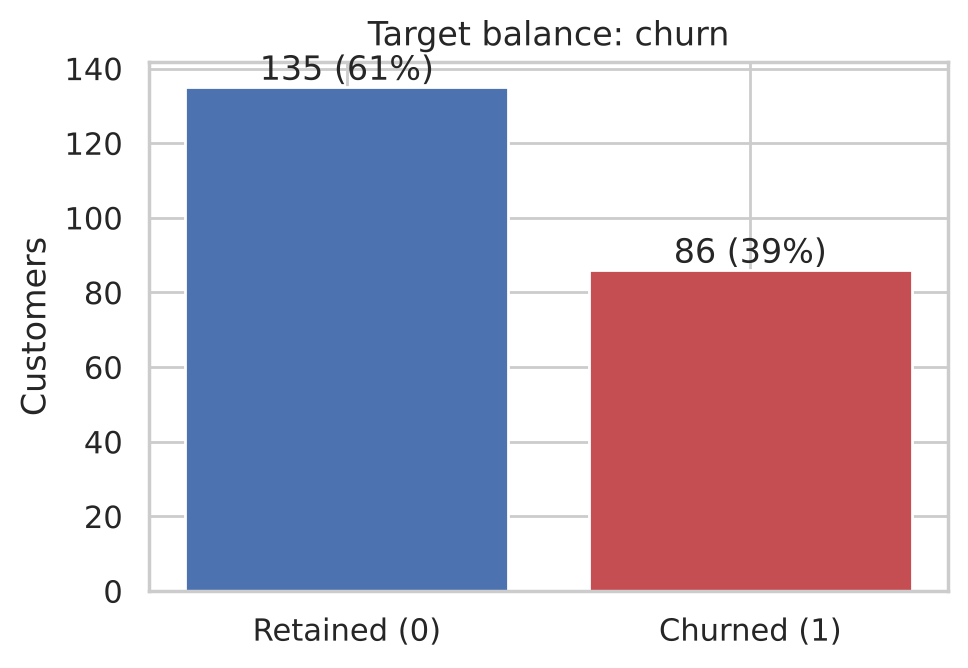

In [ ]:
fig, ax = plt.subplots(figsize=(5, 3.5))
counts = final_df[TARGET].value_counts().sort_index()
ax.bar(["Retained (0)", "Churned (1)"], counts.values, color=["#4c72b0", "#c44e52"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 2, f"{v} ({v / len(final_df):.0%})", ha="center")
ax.set_title("Target balance: churn"); ax.set_ylabel("Customers")
fig.tight_layout(); fig.savefig(FIG_DIR / "01_target_balance.png", dpi=150); plt.show()

In [ ]:
audit = leakage_audit(final_df)
audit

,feature,auc,abs_signal
0,logins_per_month,0.632127,0.632127
1,items_per_order,0.613049,0.613049
2,avg_item_price,0.396770,0.603230
3,spend_per_month,0.592722,0.592722
4,orders_per_month,0.587812,0.587812
5,delivery_missing_share,0.416408,0.583592
6,std_order_value,0.569165,0.569165
7,avg_order_value,0.567829,0.567829
8,avg_rating,0.556848,0.556848
9,share_directdebit,0.546899,0.546899


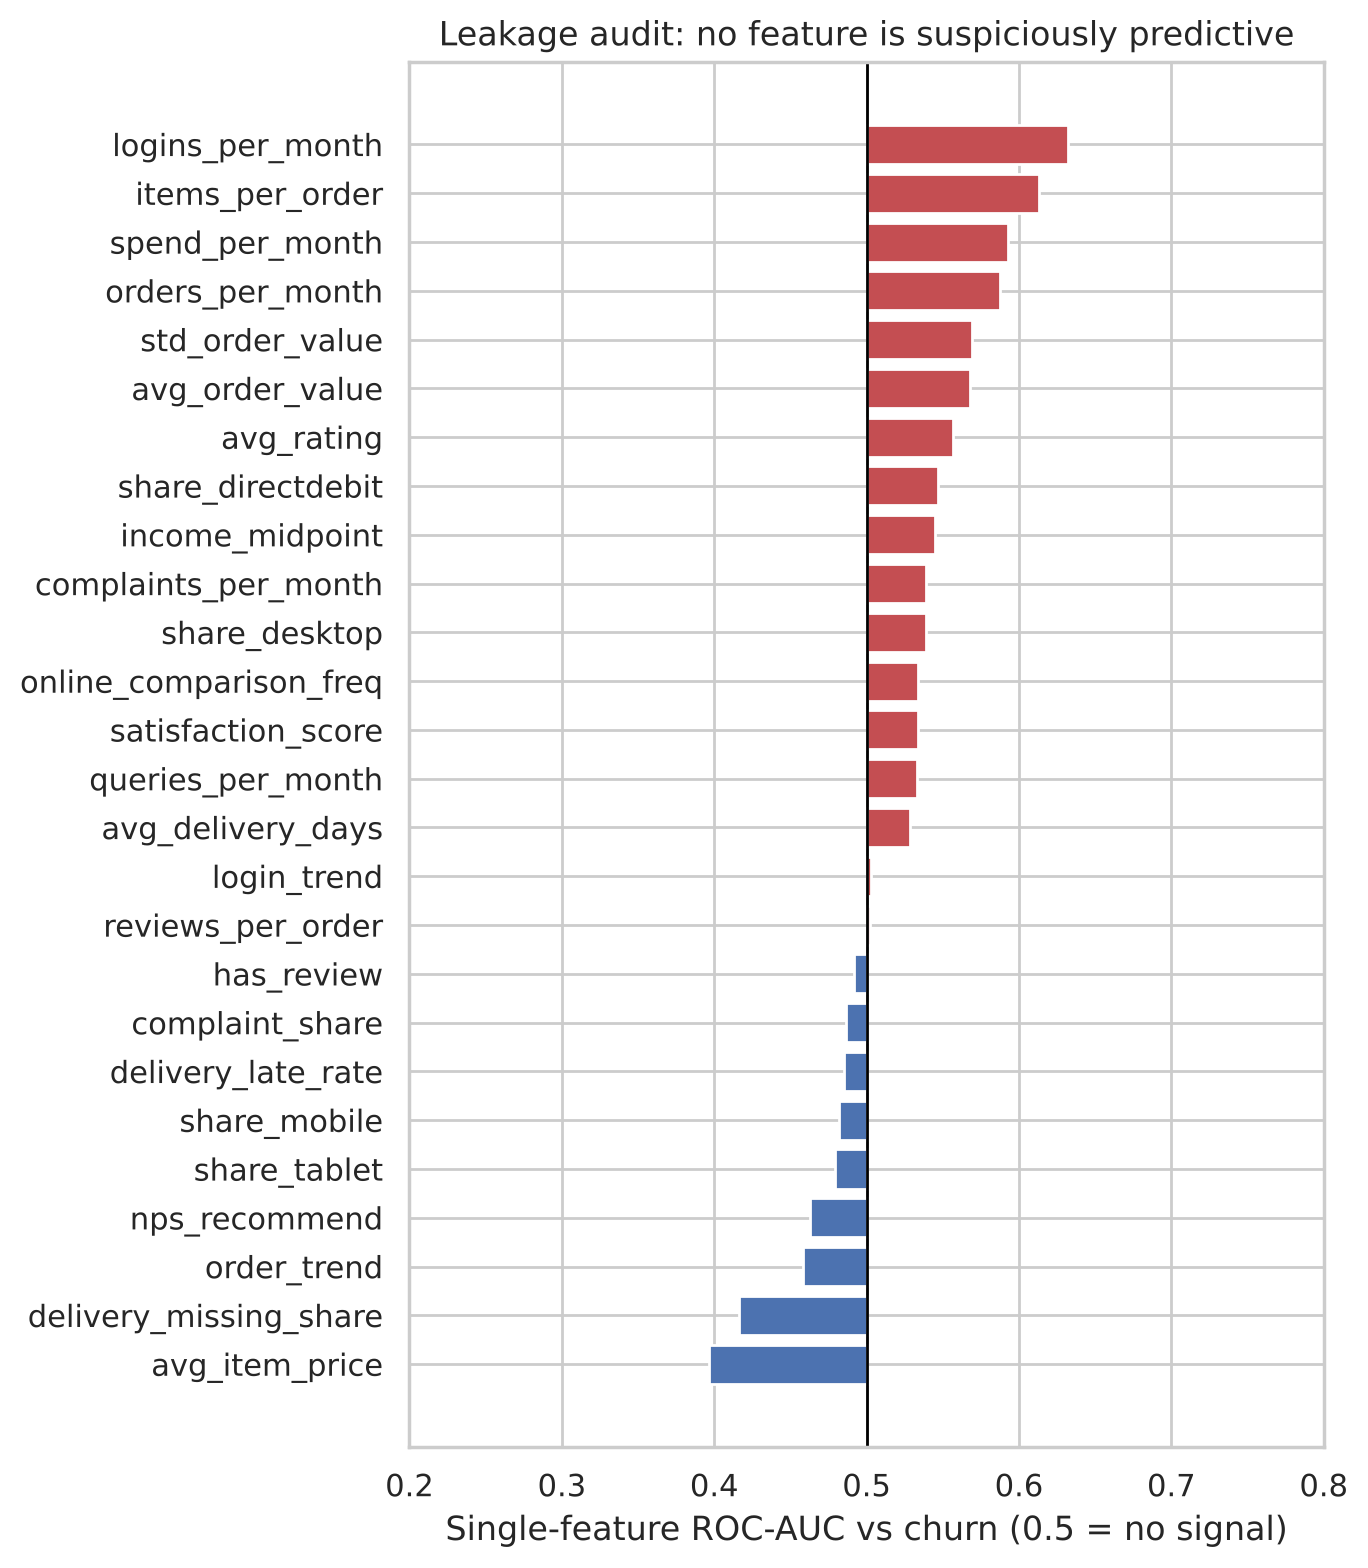

In [ ]:
# Single-feature AUC: how much does each feature separate churners from retained customers on its own?
fig, ax = plt.subplots(figsize=(7, 8))
a = audit.sort_values("auc")
ax.barh(a["feature"], a["auc"] - 0.5, left=0.5, color=np.where(a["auc"] >= 0.5, "#c44e52", "#4c72b0"))
ax.axvline(0.5, color="black", lw=1)
ax.set_xlim(0.2, 0.8); ax.set_xlabel("Single-feature ROC-AUC vs churn (0.5 = no signal)")
ax.set_title("Leakage audit: no feature is suspiciously predictive")
fig.tight_layout(); fig.savefig(FIG_DIR / "02_leakage_audit_single_feature_auc.png", dpi=150); plt.show()

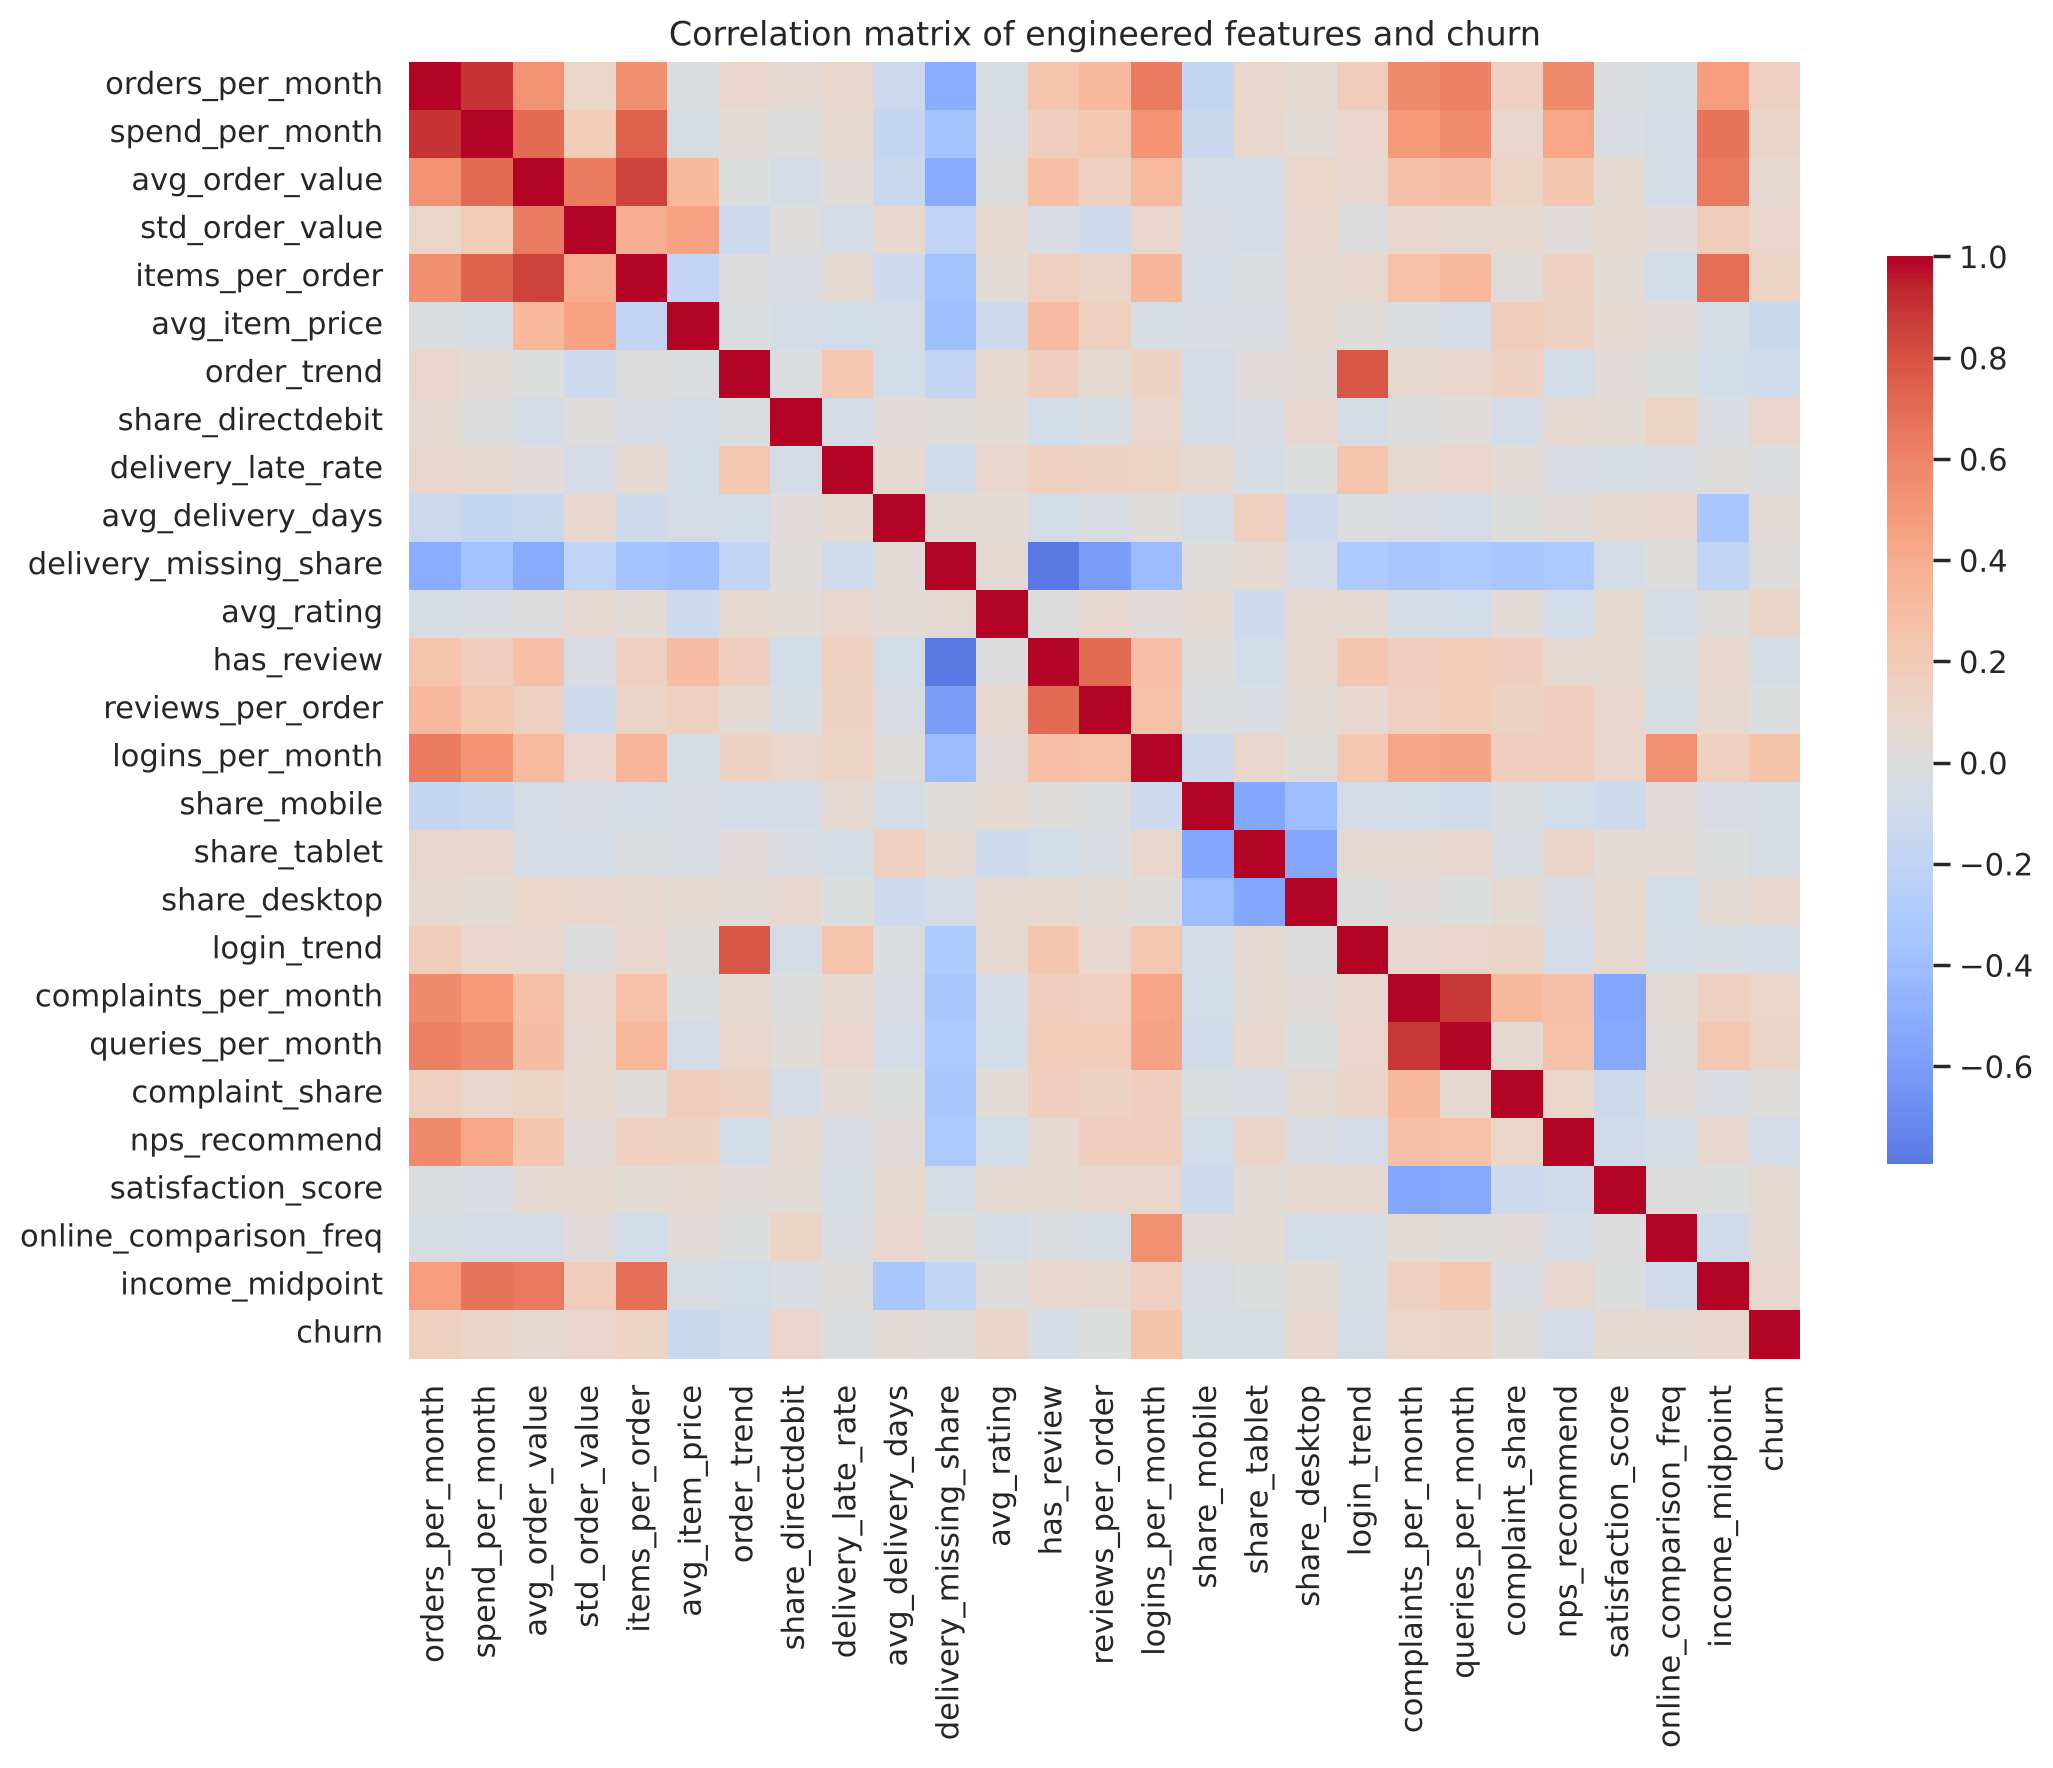

In [ ]:
fig, ax = plt.subplots(figsize=(11, 9))
corr = final_df[FEATURE_COLUMNS + [TARGET]].corr()
sns.heatmap(corr, cmap="coolwarm", center=0, ax=ax, cbar_kws={"shrink": .7}, xticklabels=True, yticklabels=True)
ax.set_title("Correlation matrix of engineered features and churn")
fig.tight_layout(); fig.savefig(FIG_DIR / "03_correlation_heatmap.png", dpi=150); plt.show()

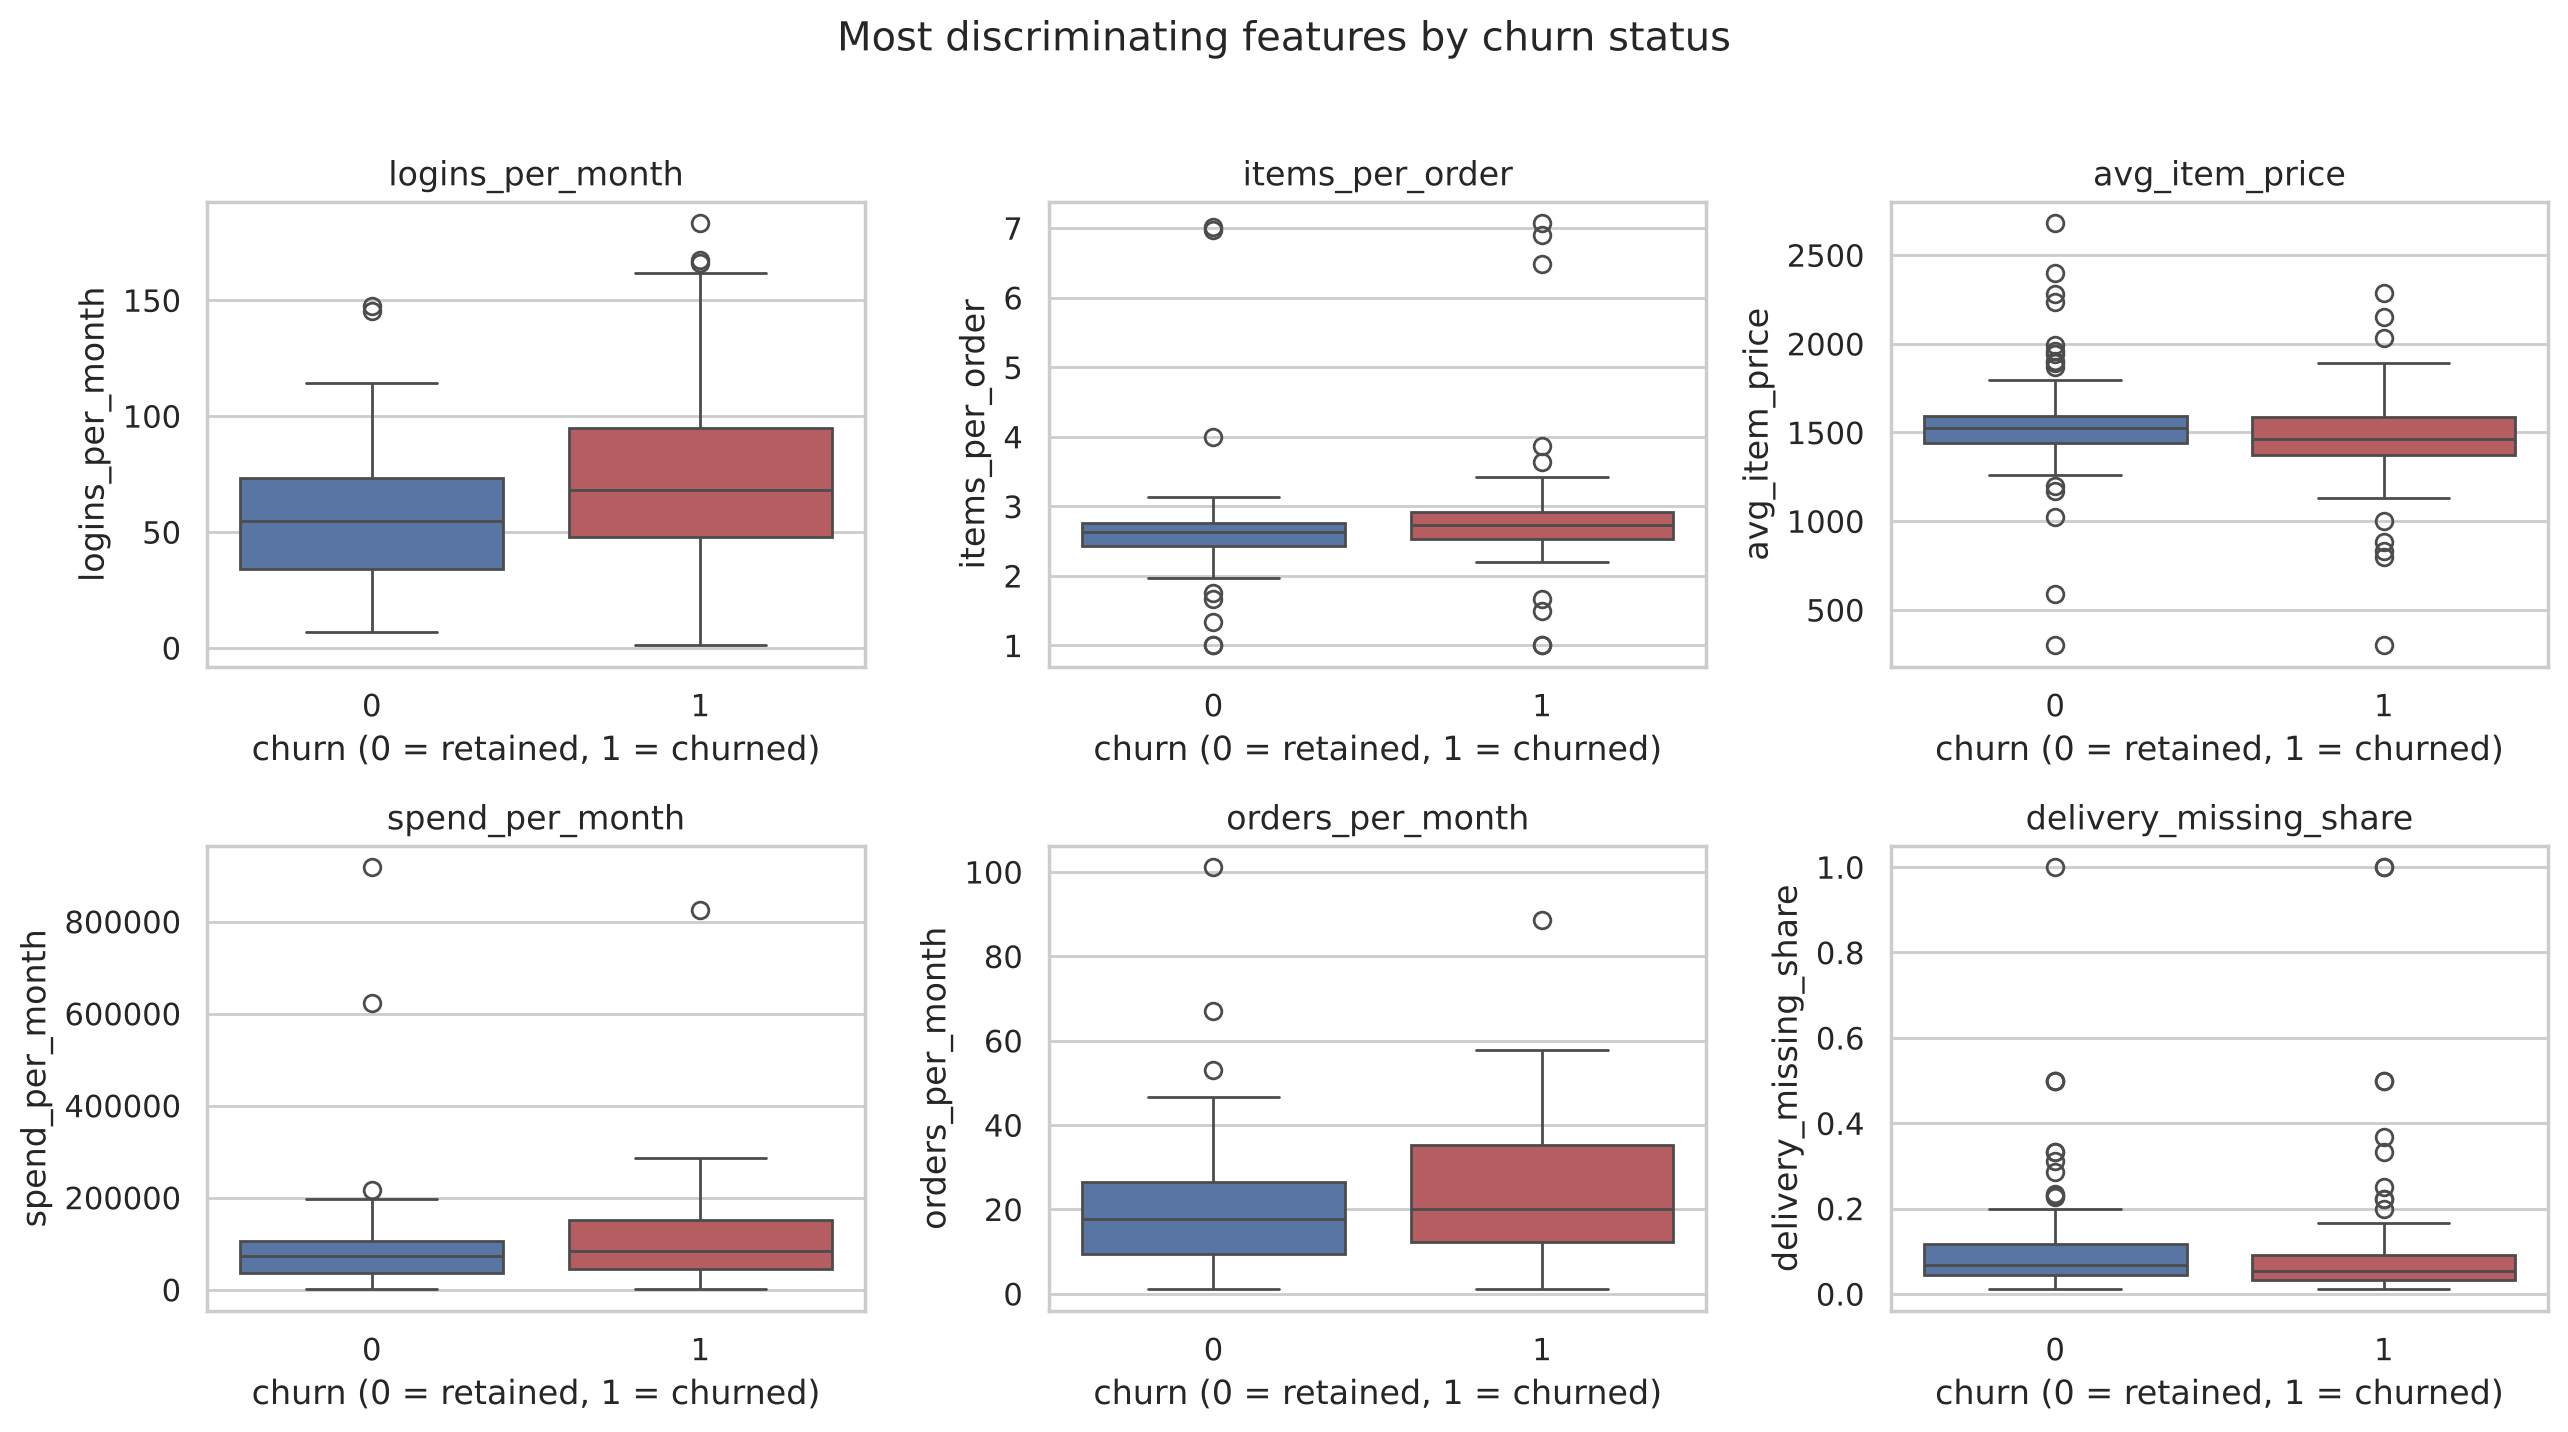

In [ ]:
top = audit["feature"].head(6).tolist()
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), top):
    sns.boxplot(data=final_df, x=TARGET, y=col, hue=TARGET, palette=["#4c72b0", "#c44e52"], legend=False, ax=ax)
    ax.set_title(col); ax.set_xlabel("churn (0 = retained, 1 = churned)")
fig.suptitle("Most discriminating features by churn status", y=1.02)
fig.tight_layout(); fig.savefig(FIG_DIR / "04_top_features_by_churn.png", dpi=150, bbox_inches="tight"); plt.show()

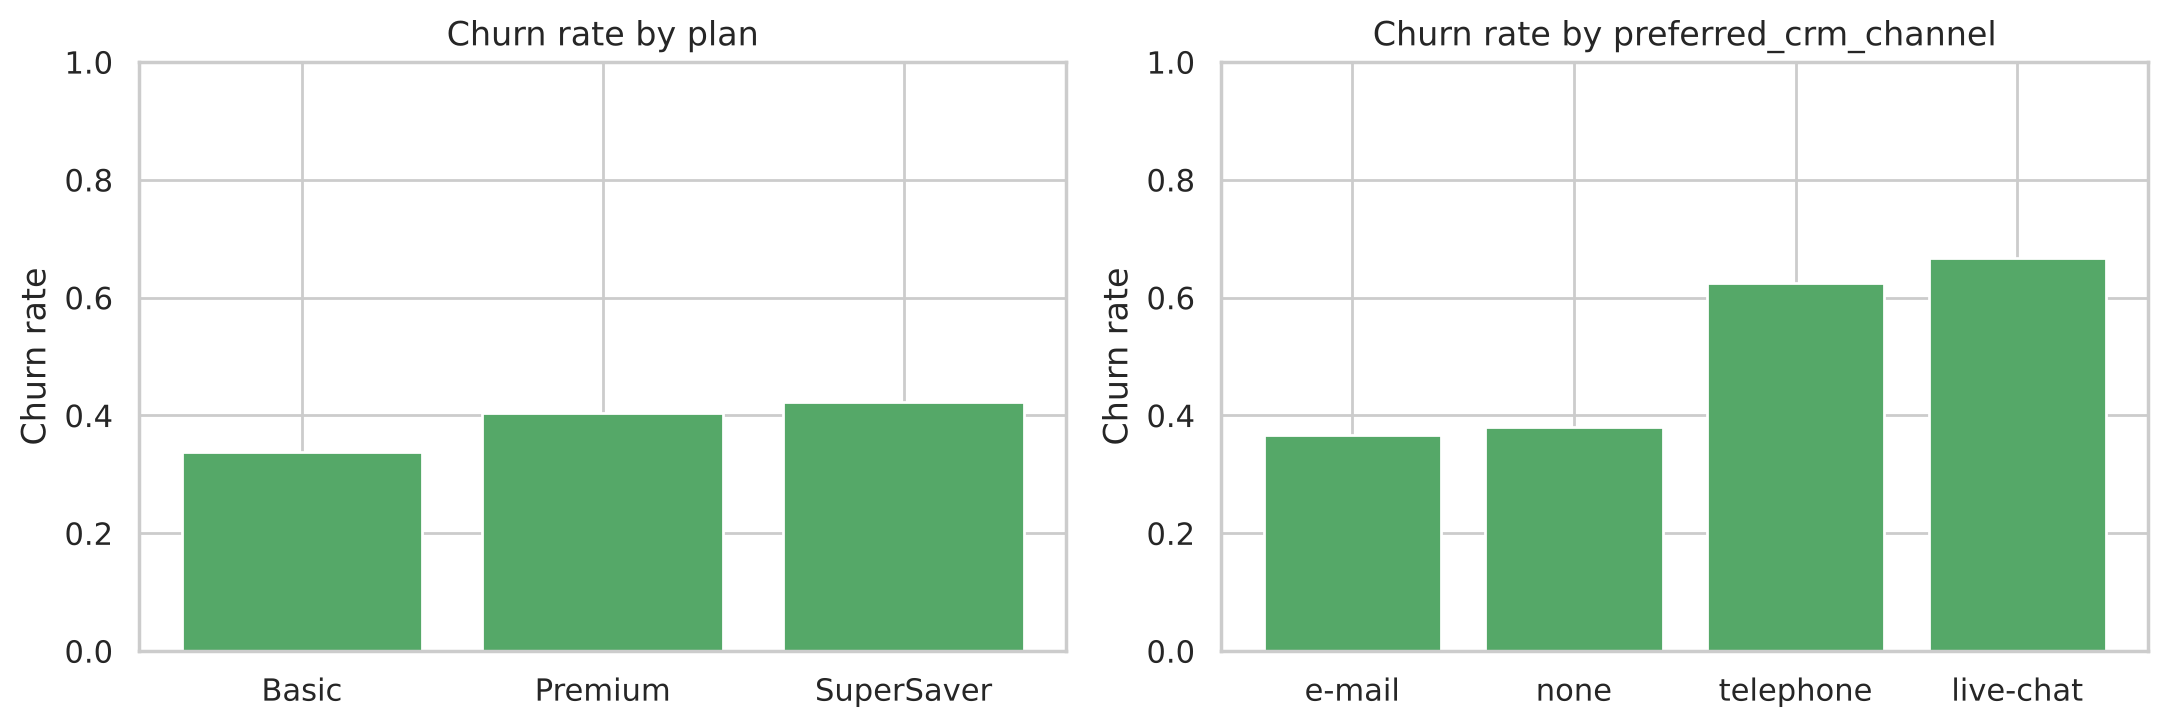

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, col in zip(axes, ["plan", "preferred_crm_channel"]):
    rate = final_df.groupby(col)[TARGET].mean().sort_values()
    ax.bar(rate.index, rate.values, color="#55a868"); ax.set_ylim(0, 1)
    ax.set_title(f"Churn rate by {col}"); ax.set_ylabel("Churn rate")
fig.tight_layout(); fig.savefig(FIG_DIR / "05_churn_rate_by_category.png", dpi=150); plt.show()

## 9. Summary, assumptions, limitations and future improvements

**Output:** `data/processed/processed_churn.parquet` — one row per customer (221), the binary target `churn`, 5 categorical and 26 numeric features, no PII.

**Assumptions about data quality**
* Missing `delivered_date` / `expected_date` (4.7% of orders, spread over the whole year) is treated as *unknown*: flagged via `delivery_missing_share`, never imputed. Delivery metrics use only orders with dates.
* A customer with no CRM contacts truly contacted support zero times (filled with 0, not imputed).
* Customers without reviews get the global mean rating **plus** the `has_review` flag, so the model can still tell imputed from real.
* The survey is a snapshot with a response from every customer; it is not timestamped, so survey answers may partly *follow* the decision to churn.

**Limitations & trade-offs**
* **Leakage vs. information:** dropping tenure / end date / recency costs predictive power, but a model built on them would be meaningless in production, where we need to predict churn *before* it happens. 
* Imputation statistics (global mean/median) are computed on the full dataset before the train/test split in Task 3, which is a very small optimistic bias; in production they would be fitted on training data only (e.g. inside a Spark ML pipeline).
* With only 221 customers, metrics in Task 3 will have wide confidence intervals.
* The observation window ends at the last activity, so a retained customer's window is ≈ until the data snapshot, while a churner's ends at cancellation. Rates are therefore comparable, but not identical in exposure.

**Future improvements**
* Replace the pandas pipeline with Spark/SQL (or DuckDB) if the data grows beyond memory; add a scheduler (Airflow/cron) and persistent run logs.
* Convert the unit tests into a `pytest` suite and add schema contracts (e.g. `pandera` / Great Expectations).
* Add time-aware features at fixed "snapshot dates" (e.g. features as of 30 days before renewal) to get a proper point-in-time training set.